# Financial Mathematics with Python – UNIT 2
**Goal:** Understand the financial concept first, then run a small Python example.

Topics: Linearity → CAPM/SML → APT → Multivariate Factor Regression → Linear Programming → Integer Programming → Matrix Equations → LU/Cholesky/QR → Nonlinearity → Root Finding with SciPy.



In [3]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.optimize import linprog, root_scalar
from scipy.linalg import lu, cholesky, qr

df = pd.read_csv('/content/simple_finance_dataset.csv')
print(df.head())

   Stock_A_Return  Stock_B_Return  Market_Return  Risk_Free  Inflation  \
0           0.020           0.015          0.018      0.005      0.040   
1           0.015           0.020          0.016      0.005      0.042   
2          -0.010          -0.005         -0.008      0.005      0.041   
3           0.030           0.025          0.028      0.005      0.043   
4           0.012           0.010          0.011      0.005      0.044   

   Interest_Rate  GDP_Growth  Portfolio_Return  
0          0.060       0.065             0.018  
1          0.061       0.067             0.017  
2          0.059       0.064            -0.007  
3          0.062       0.068             0.027  
4          0.063       0.069             0.011  


## 1. Importance of Linearity in Finance
Linearity means a change in an input produces a proportional/additive change in the output. It makes portfolio returns, factor models and optimization easier to calculate and interpret.

In [4]:
# Portfolio return is a linear combination of asset returns
weights = np.array([0.6, 0.4])
portfolio = weights[0]*df['Stock_A_Return'] + weights[1]*df['Stock_B_Return']
print('First 5 portfolio returns:', portfolio.head().round(4).tolist())

# Check linearity: doubling both positions doubles the calculated contribution
x = np.array([100, 200, 300])
print('Linear transformation 2x:', 2*x)

First 5 portfolio returns: [0.018, 0.017, -0.008, 0.028, 0.0112]
Linear transformation 2x: [200 400 600]


## 2. CAPM and the Security Market Line (SML)
CAPM: expected return depends on the risk-free rate, beta and expected market return.


The SML is the straight line relating beta to expected return.

beta=0.0, expected return=5.00%
beta=0.5, expected return=7.50%
beta=1.0, expected return=10.00%
beta=1.5, expected return=12.50%
beta=2.0, expected return=15.00%


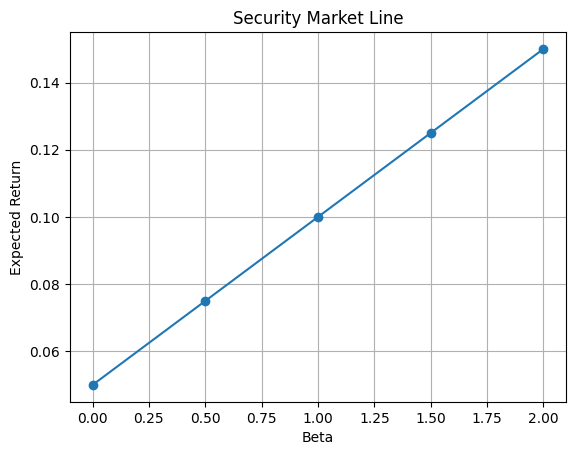

In [5]:
rf = 0.05
rm = 0.10
betas = np.array([0, 0.5, 1, 1.5, 2])
expected = rf + betas*(rm-rf)
for b,e in zip(betas,expected): print(f'beta={b:.1f}, expected return={e:.2%}')

plt.plot(betas, expected, marker='o')
plt.xlabel('Beta'); plt.ylabel('Expected Return'); plt.title('Security Market Line')
plt.grid(True); plt.show()

## 3. Arbitrage Pricing Theory (APT)
APT allows several systematic factors. A simple two-factor model is:


Here we use inflation and interest-rate changes as simple classroom factors.

In [6]:
df['Inflation_Change'] = df['Inflation'].diff().fillna(0)
df['Rate_Change'] = df['Interest_Rate'].diff().fillna(0)
b1, b2 = 1.2, -0.8
apt_return = df['Risk_Free'] + b1*df['Inflation_Change'] + b2*df['Rate_Change']
print(pd.DataFrame({'Actual':df['Portfolio_Return'], 'APT_Estimate':apt_return}).round(4))

   Actual  APT_Estimate
0   0.018        0.0050
1   0.017        0.0066
2  -0.007        0.0054
3   0.027        0.0050
4   0.011        0.0054
5  -0.002        0.0054
6   0.021        0.0042
7   0.016        0.0062
8  -0.009        0.0054
9   0.021        0.0054


## 4. Multivariate Linear Regression / Factor Model
We estimate a return using several factors at once. In matrix form: \(y=X\beta+\epsilon\).

In [7]:
from sklearn.linear_model import LinearRegression
X = df[['Inflation','Interest_Rate','GDP_Growth']]
y = df['Portfolio_Return']
model = LinearRegression().fit(X,y)
print('Intercept:', model.intercept_)
print('Coefficients:', dict(zip(X.columns, model.coef_.round(4))))
print('R^2:', round(model.score(X,y),4))

Intercept: -0.30088831018518497
Coefficients: {'Inflation': np.float64(-12.0787), 'Interest_Rate': np.float64(7.2109), 'GDP_Growth': np.float64(5.7104)}
R^2: 0.7318


## 5. Linear Programming (LP)
Example: choose quantities of two investment products to maximize return under a budget and risk/resource constraints.



In [8]:
# scipy minimizes, so maximize by using negative objective coefficients
c = [-40, -30]
A = [[4,3],[2,1]]
b = [60,30]
res = linprog(c, A_ub=A, b_ub=b, bounds=[(0,None),(0,None)], method='highs')
print('Optimal x,y:', res.x)
print('Maximum objective value:', -res.fun)

Optimal x,y: [ 0. 20.]
Maximum objective value: 600.0


## 6. Integer Programming
Now require whole-number decisions. A simple approach for a tiny classroom problem is to enumerate feasible integer combinations. For larger problems, use a dedicated mixed-integer solver.

In [9]:
best = None
for x in range(0,31):
    for y in range(0,31):
        if 4*x+3*y <= 60 and 2*x+y <= 30:
            value = 40*x+30*y
            if best is None or value > best[0]: best=(value,x,y)
print('Integer optimum (value, x, y):', best)

Integer optimum (value, x, y): (600, 0, 20)


## 7. Solving Linear Equations Using Matrices
Suppose two financial activities satisfy:
\(2x+y=8\) and \(x+3y=9\). In matrix form, \(AX=b\).

In [10]:
A = np.array([[2,1],[1,3]], dtype=float)
b = np.array([8,9], dtype=float)
x = np.linalg.solve(A,b)
print('Solution:', x)
print('Check Ax:', A@x)

Solution: [3. 2.]
Check Ax: [8. 9.]


## 8. LU Decomposition
LU decomposes a matrix into lower and upper triangular factors. It is useful for repeatedly solving systems with the same coefficient matrix.

In [11]:
P,L,U = lu(A)
print('P=\n',P,'\nL=\n',L,'\nU=\n',U)
print('Check P@A equals L@U:', np.allclose(P@A,L@U))

P=
 [[1. 0.]
 [0. 1.]] 
L=
 [[1.  0. ]
 [0.5 1. ]] 
U=
 [[2.  1. ]
 [0.  2.5]]
Check P@A equals L@U: True


## 9. Cholesky Decomposition
Cholesky requires a symmetric positive-definite matrix. A covariance matrix is a natural finance example.

In [12]:
C = np.array([[4,2],[2,3]], dtype=float)
Lc = cholesky(C, lower=True)
print('Cholesky L=\n', Lc)
print('Check L L.T=\n', Lc@Lc.T)

Cholesky L=
 [[2.         0.        ]
 [1.         1.41421356]]
Check L L.T=
 [[4. 2.]
 [2. 3.]]


## 10. QR Decomposition
QR writes \(A=QR\). It is numerically useful for least-squares regression.

In [13]:
X = np.array([[1,1],[1,2],[1,3],[1,4]], dtype=float)
y = np.array([2,3,5,6], dtype=float)
Q,R = qr(X, mode='economic')
beta = np.linalg.solve(R, Q.T@y)
print('Q=\n',Q,'\nR=\n',R)
print('Regression coefficients using QR:', beta)

Q=
 [[-0.5         0.67082039]
 [-0.5         0.2236068 ]
 [-0.5        -0.2236068 ]
 [-0.5        -0.67082039]] 
R=
 [[-2.         -5.        ]
 [ 0.         -2.23606798]]
Regression coefficients using QR: [0.5 1.4]


## 11. Nonlinearity in Finance
Real financial relationships may not be linear. For example, a simple nonlinear cost/return function can include a squared term: \(y=2x+0.5x^2\).

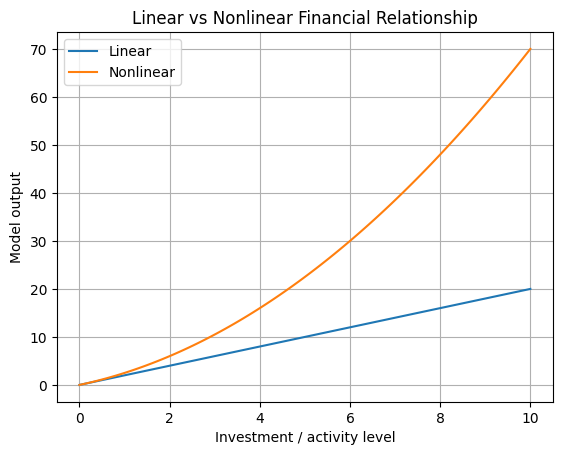

In [14]:
x = np.linspace(0,10,100)
y_linear = 2*x
y_nonlinear = 2*x + 0.5*x**2
plt.plot(x,y_linear,label='Linear')
plt.plot(x,y_nonlinear,label='Nonlinear')
plt.xlabel('Investment / activity level'); plt.ylabel('Model output')
plt.title('Linear vs Nonlinear Financial Relationship'); plt.legend(); plt.grid(True); plt.show()

## 12. Nonlinearity Modeling
Fit a polynomial model to demonstrate that the relationship can curve rather than remain a straight line.

In [15]:
x = np.array([1,2,3,4,5,6],float)
y = np.array([2.2,4.1,7.0,10.2,14.8,20.1])
coef = np.polyfit(x,y,2)
print('Quadratic coefficients:', coef)
pred = np.polyval(coef,x)
print(pd.DataFrame({'x':x,'actual':y,'predicted':pred}).round(2))

Quadratic coefficients: [0.425      0.59071429 1.22      ]
     x  actual  predicted
0  1.0     2.2       2.24
1  2.0     4.1       4.10
2  3.0     7.0       6.82
3  4.0    10.2      10.38
4  5.0    14.8      14.80
5  6.0    20.1      20.06


## 13. Root-Finding Algorithms
A root is a value of x for which \(f(x)=0\). In finance, roots can represent a break-even point, yield, implied rate, or price condition.

We compare a simple **bisection** idea with SciPy's `root_scalar`.

In [16]:
def f(x):
    return x**2 - 9

# Bisection: the root is bracketed between 0 and 5
lo, hi = 0, 5
for _ in range(30):
    mid=(lo+hi)/2
    if f(lo)*f(mid) <= 0: hi=mid
    else: lo=mid
print('Bisection root:', mid)

sol = root_scalar(f, bracket=[0,5], method='bisect')
print('SciPy bisection root:', sol.root)

sol2 = root_scalar(f, bracket=[0,5], method='brentq')
print('SciPy Brent root:', sol2.root)

Bisection root: 3.0000000027939677
SciPy bisection root: 3.000000000000682
SciPy Brent root: 3.0


## 14. Finance Root-Finding Example: Break-even Investment
Suppose profit is \(P(x)=x^2-10x+21\). Break-even occurs when profit = 0.

In [17]:
def profit(x): return x**2 - 10*x + 21
r1 = root_scalar(profit, bracket=[0,4], method='brentq')
r2 = root_scalar(profit, bracket=[6,10], method='brentq')
print('Break-even points:', r1.root, r2.root)

Break-even points: 3.0 6.999999999999999


#Exercise TO BE DONE

1. Change CAPM beta and observe expected return.
2. Add a third factor to the APT example.
3. Change LP returns and constraints.
4. Compare integer and continuous LP solutions.
5. Replace the matrix A and solve again.
6. Try Cholesky on a covariance matrix from the dataset.
7. Fit linear and quadratic models and compare errors.
8. Try `root_scalar` with `bisect` and `brentq` on another nonlinear financial equation.